In [200]:
import emcee
import corner
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import pickle
from uncertainties import ufloat
from uncertainties.umath import *
from uncertainties import unumpy as unp
from astropy import units as u
from astropy.cosmology import FlatLambdaCDM
from asymmetric_uncertainty_mod import a_u, pos_errors, neg_errors
cosmo=FlatLambdaCDM(70, 0.3)
from functions.statistics_functions import chi_squared
from functions.load_data_and_var import generate_nfws_from_combined_dataset_werr, load_data_and_var

In [12]:
data, var = load_data_and_var()

In [13]:
data

,MCXC,OName,L500,Sub-Cat,RXC,Flux,e_Flux,ObsLum,LumCor,z_x,z_y,MSZ,E_MSZ,e_MSZ,L_err
1,J0003.8+0203,RXCJ0003.8+0203,0.846881,REFLEX,RXCJ0003.8+0203,4.155,18.8,0.855,0.929,0.0924,0.0924,2.238774,0.282160,0.301448,0.136697
2,J0006.0-3443,RXCJ0006.0-3443,1.809494,REFLEX,RXCJ0006.0-3443,5.832,13.6,1.875,1.995,0.1147,0.1147,4.001657,0.248869,0.226974,0.211612
3,J0011.3-2851,RXCJ0011.3-2851,1.086002,REFLEX,RXCJ0011.3-2851,12.014,9.0,1.089,1.197,0.0620,0.0620,2.606369,0.182667,0.188038,0.086421
4,J0013.6-1930,RXCJ0013.6-1930,1.236332,REFLEX,RXCJ0013.6-1930,6.071,11.3,1.285,1.353,0.0940,0.0940,2.756623,0.233331,0.245311,0.124151
5,J0014.3-6604,RXCJ0014.3-6604,2.827248,REFLEX,RXCJ0014.3-6604,4.485,13.8,2.907,3.160,0.1599,0.1599,3.030337,0.328876,0.347930,0.313951
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
219,J2344.2-0422,RXCJ2344.2-0422,1.852614,REFLEX,RXCJ2344.2-0422,12.638,7.4,1.855,2.061,0.0786,0.0786,3.116566,0.176734,0.208566,0.119201
220,J2347.7-2808,RXCJ2347.7-2808,1.029501,REFLEX,RXCJ2347.7-2808,49.578,3.8,1.014,1.127,0.0300,0.0300,1.480293,0.114748,0.107849,0.035782
222,J2354.2-1024,RXCJ2354.2-1024,1.336537,REFLEX,RXCJ2354.2-1024,9.622,12.1,1.337,1.469,0.0765,0.0765,2.761984,0.216913,0.225417,0.140711
223,J2357.0-3445,RXCJ2357.0-3445,1.629622,REFLEX,RXCJ2357.0-3445,32.663,5.5,1.698,1.787,0.0475,0.0475,2.468719,0.163126,0.149009,0.084849


In [14]:
var

<Quantity [0.13669688, 0.21161239, 0.08642148, 0.12415091, 0.31395135,
           0.28467254, 0.04313421, 0.30712575, 0.16383056, 0.09261681,
           0.15256437, 0.22812092, 0.07296769, 0.08604049, 0.03988421,
           0.01343087, 0.04116165, 0.05525675, 0.26656201, 0.41248653,
           0.24933768, 0.06528887, 0.08460659, 0.14422505, 0.08367643,
           0.13353712, 0.0529359 , 0.09599615, 0.6851627 , 0.51102524,
           0.16839514, 0.0869296 , 0.06419554, 0.08802421, 0.05397229,
           0.05094809, 0.0646779 , 0.0597375 , 0.0924723 , 0.08103255,
           0.27184123, 0.04419837, 0.22532887, 0.1261032 , 0.11222508,
           0.30263738, 0.72197788, 0.3749163 , 0.34853621, 0.08214843,
           0.02087316, 0.1348567 , 0.280594  , 0.03238405, 0.14024308,
           0.04511257, 0.2261462 , 0.23120279, 0.12949436, 0.04108116,
           0.04055361, 0.32178168, 0.04214704, 0.44789664, 0.12270038,
           0.11067255, 0.11531432, 0.23934259, 0.46271074, 0.3580544 ,
      

In [15]:
all_nfws = generate_nfws_from_combined_dataset_werr(data, var)

In [16]:
nfws = [nfw for nfw in all_nfws if nfw.energies.is_virialized_gaspari]

In [17]:
len(nfws)

111

In [18]:
len(all_nfws)

173

In [32]:
test_nfw=all_nfws[50]

In [23]:
test_nfw.M500.value/1e14, test_nfw.L500.value

(2.2387739999999994, 0.846881)

In [66]:
from scipy.integrate import quad
def average_density(r, nfw):
    r500 = nfw.R500
    c500 = nfw.c500
    volume = (4 / 3) * np.pi * r**3
    integral, _ = quad(lambda x: 4 * np.pi * x**2 * nfw.rho_tot(x, r500, c500), 0, r)
    return integral / volume

In [110]:
from astropy import constants as const
def vc2(r, nfw):
    return (const.G*nfw.M_enc(r)*u.Msun/(r*u.Mpc)).to((u.m/u.s)**2).value

In [113]:
def integrand(r, nfw):
    return (4*np.pi*r**2*nfw.rho_tot(r).value*vc2(r, nfw))#.to(u.Msun/u.Mpc * (u.m/u.s)**2).value

In [134]:
def Ps(nfw, Rvir, R80):
    V = 4*np.pi/3 * (Rvir**3 - (R80)**3)
    #print(integrand(Rvir, nfw))
    integral, _ = quad(lambda r: integrand(r, nfw), R80, Rvir)
    return integral/(3*V)

In [190]:
from scipy.optimize import brentq
def surface_pressure_energy(nfw):
    #overdensity_const = 178*cosmo.Om(nfw.z)**(0.45)
    avg_rho_within_rvir = (nfw.overdensity_const*nfw.rho_c).to(u.Msun/u.Mpc**3).value
    
    Rvir= brentq(lambda r: average_density(r, nfw) - avg_rho_within_rvir, 1e-5, 10*nfw.R500.value)
    Mvir = (4*np.pi/3*Rvir**3 * avg_rho_within_rvir)
    
    R80 = brentq(lambda r: nfw.M_enc(r).value - 0.8*Mvir, 1e-5, Rvir)
    pressure = Ps(nfw, Rvir, R80)
    
    R90 = brentq(lambda r: nfw.M_enc(r).value - 0.9*Mvir, R80, Rvir)
    Es= ((4*np.pi*R90**3 * pressure)*(u.Msun*(u.m/u.s)**2))#.to(u.erg) 
    return Es
    
    #return overdensity_const
    #return avg_rho_within_rvir

In [191]:
surface_pressures = [surface_pressure_energy(nfw).value for nfw in all_nfws]

In [192]:
p_err_upper = np.multiply([nfw.M500.plus/nfw.M500.value for nfw in all_nfws], surface_pressures)
p_err_lower = np.multiply([nfw.M500.minus/nfw.M500.value for nfw in all_nfws], surface_pressures)

Text(0, 0.5, 'surface pressure (Msun *(m/s)^2)')

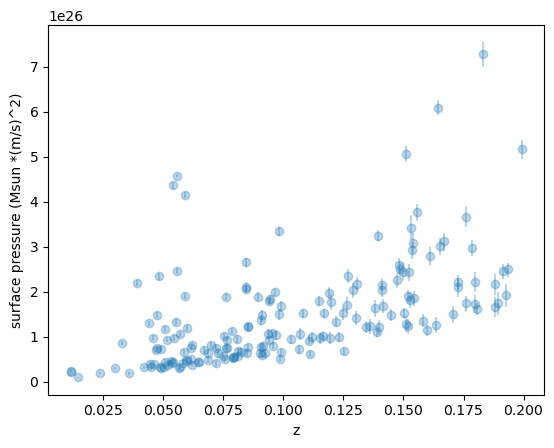

In [193]:
plt.errorbar([nfw.z for nfw in all_nfws], surface_pressures, yerr=[p_err_lower, p_err_upper], fmt='o', linestyle='None', alpha=0.3)

plt.xlabel('z')
plt.ylabel('surface pressure (Msun *(m/s)^2)')

In [92]:
test_nfw.rho_tot(rs)[0].value

4.805363412076901e+19

In [109]:
# rs = np.logspace(-5, 2)*test_nfw.R500.value
# plt.loglog(rs, [average_density(r, test_nfw) for r in rs], label='avg density within r')
# plt.loglog(rs, test_nfw.rho_tot(rs), label='density at r')
# plt.legend()
# plt.xlabel("r (Mpc)")
# plt.ylabel('rho')

In [116]:
surface_pressure_energy(test_nfw)

4.064845926737608e+25


<Quantity 3.81124362e+62 erg>

In [35]:
test_nfw.overdensity_const

104.21227471160876

In [60]:
test_nfw.R500.value

0.7260977271455843

In [126]:
(test_nfw.energies.T500().value*u.GeV).to(u.erg) #of a particle

<Quantity 4.23961243e-09 erg>

In [129]:
(test_nfw.energies.abs_potential_energy.value*u.GeV).to(u.erg) # of a particle

<Quantity 9.879396e-09 erg>

In [130]:
from cluster_class.cluster_functions import T500_from_L500, E_tot

In [131]:
E_tot(test_nfw)

2.4927755764496934e+63

In [141]:
def beta(nfw, L=None, surface_pressure=True): # remove ".value" once ive gotten units figured out
    G_conv = (const.G/const.c**2).to(u.Mpc/u.Msun)
    pe = G_conv * (nfw.M500.value)**2*u.Msun**2/(nfw.R500.value*u.Mpc)
    
    if not L:
        L = nfw.L500.value
    xmin = 0.001
    xmax = 1
    xs = np.logspace(np.log10(xmin), np.log10(xmax), num=50)
    rs = xs*nfw.R500
    
    
    Tbs = np.array([T.value for T in np.asarray(nfw.T_g(rs, match_gaspari=True))]) # in GeV
    Tbs_norm = Tbs/Tbs[-1] # unitless
    Tbs_Ldep = Tbs_norm * T500_from_L500(np.log10(L))
    nbs = [n.value for n in np.asarray(nfw.n_e(rs))] # in 1/Mpc^3
    ke_b = (np.trapz(4*np.pi * rs**2 * 3./2* np.multiply(Tbs_Ldep,nbs),rs)).value*u.GeV
    
    avg_rho_x = nfw.M500.value/(4./3*np.pi*nfw.R500.value**3) # Msun/Mpc3
    #Tx_by_mx_float = [tm.value for tm in nfw.Tx_by_mx]
    ke_x = (np.trapz(4*np.pi*rs**2 * 3./2*avg_rho_x*nfw.Tx_by_mx, rs).value)*u.Msun
    #ke_x = 0 * u.erg
    if surface_pressure:
        return (2*(ke_x + ke_b) - surface_pressure_energy(nfw))/pe - 1
    else:
        return (2*(ke_x + ke_b))/pe - 1
    #return (pe+ke_b+ke_x).to(u.erg, equivalencies=u.mass_energy()).value

In [212]:
def beta(nfw, L=None, surface_pressure=True): # remove ".value" once ive gotten units figured out
    G_conv = ((const.G).to(u.Mpc/u.Msun * u.m**2/u.s**2)).value
    pe = G_conv * (nfw.M500)**2/(nfw.R500) # M is in Msun, R is in Mpc, so pe is in Msun * (m/s)^2
    
    if not L:
        L = nfw.L500
    xmin = 0.001
    xmax = 1
    xs = np.logspace(np.log10(xmin), np.log10(xmax), num=50)
    rs = xs*nfw.R500
    
    
    Tbs = np.array([T.value for T in np.asarray(nfw.T_g(rs, match_gaspari=True))]) # in GeV
    Tbs_norm = Tbs/Tbs[-1] # unitless
    Tbs_Ldep = Tbs_norm * T500_from_L500(np.log10(L))
    nbs = [n.value for n in np.asarray(nfw.n_e(rs))] # in 1/Mpc^3
    ke_b = (np.trapz(4*np.pi * rs**2 * 3./2* np.multiply(Tbs_Ldep,nbs),rs))*(u.GeV.to(u.Msun * u.m**2/u.s**2)) # in GeV
    
    avg_rho_x = nfw.M500/(4./3*np.pi*nfw.R500**3) # Msun/Mpc3
    #Tx_by_mx_float = [tm.value for tm in nfw.Tx_by_mx]
    ke_x = (np.trapz(4*np.pi*rs**2 * 3./2*avg_rho_x*nfw.Tx_by_mx, rs))*(const.c**2).value # in Msun * (m/s)^2
    #ke_x = 0 * u.erg
    if surface_pressure:
        #print(ke_x, ke_b, surface_pressure_energy(nfw), pe)
        sp = surface_pressure_energy(nfw).value
        surface_pressure_energy_err = a_u(sp, pos_err=nfw.M500.plus/nfw.M500.value * sp, neg_err=nfw.M500.plus/nfw.M500.value * sp)
        return (2*(ke_x + ke_b) - surface_pressure_energy_err)/(-1*pe) + 1
        
    else:
        return (2*(ke_x + ke_b))/pe - 1
    #return (pe+ke_b+ke_x).to(u.erg, equivalencies=u.mass_energy()).value

In [213]:
beta(test_nfw)

In [214]:
betas = [beta(nfw) for nfw in all_nfws]
betas_values = [b.value for b in betas]
betas_pos_err = [b.plus for b in betas]
betas_neg_err = [b.minus for b in betas]

In [215]:
len(betas)

173

Text(0, 0.5, 'beta')

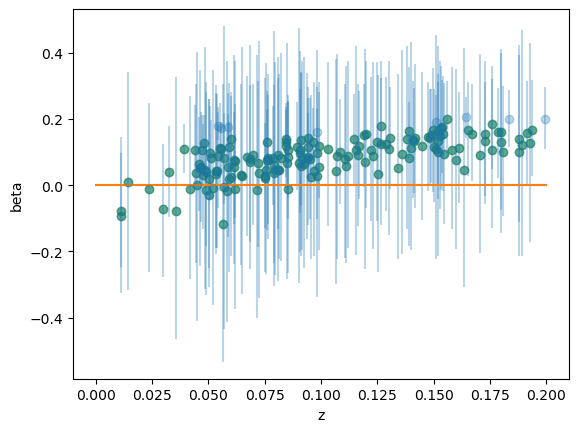

In [224]:
plt.errorbar([nfw.z for nfw in all_nfws], betas_values, yerr=[betas_neg_err, betas_pos_err], fmt='o', linestyle='None', alpha=0.3)
plt.scatter([nfw.z for nfw in virialized_nfws], virialized_betas, color='green', alpha=0.5)
plt.plot([0,0.2], [0, 0])
plt.xlabel('z')
plt.ylabel('beta')

In [219]:
def is_virialized_sp(nfw):
    b = beta(nfw)
    if b<=0:
        if b.value + 2*b.plus >=0:
            return True
    elif b>=0:
        if b.value - 2*b.minus <=0:
            return True
    else:
        return False

In [220]:
virialized_nfws = [nfw for nfw in all_nfws if is_virialized_sp(nfw)]
len(virialized_nfws)

165

In [233]:
with open('data/virialized_nfws_sp.pkl', 'wb') as file:
    pickle.dump(virialized_nfws, file)

In [221]:
virialized_betas = [beta(nfw).value for nfw in virialized_nfws]

In [142]:
betas_surface_pressure = [beta(nfw) for nfw in all_nfws]

In [143]:
betas_no_surface_pressure = [beta(nfw, surface_pressure=False) for nfw in all_nfws]

(array([12., 27., 39., 41., 25., 14., 10.,  0.,  4.,  1.]),
 array([0.09144455, 0.12006967, 0.14869479, 0.17731991, 0.20594503,
        0.23457015, 0.26319527, 0.29182039, 0.32044551, 0.34907063,
        0.37769575]),
 <BarContainer object of 10 artists>)

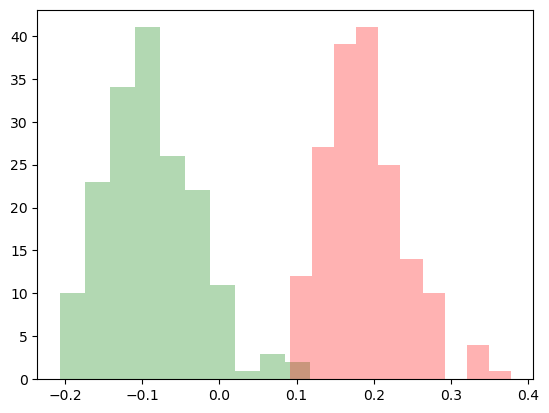

In [146]:
plt.hist(betas_surface_pressure, alpha=0.3, color='green')
plt.hist(betas_no_surface_pressure, alpha=0.3, color='red')

(array([12., 27., 39., 41., 25., 14., 10.,  0.,  4.,  1.]),
 array([0.09144455, 0.12006967, 0.14869479, 0.17731991, 0.20594503,
        0.23457015, 0.26319527, 0.29182039, 0.32044551, 0.34907063,
        0.37769575]),
 <BarContainer object of 10 artists>)

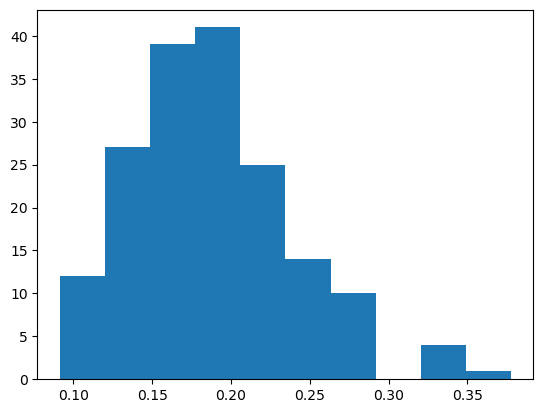

In [145]:
plt.hist(betas_no_surface_pressure)

In [225]:
equilibrium_clusters = []
eq_heating_rates = []
eq_cooling_rates = []
for n in virialized_nfws:
    h = n.total_heating_rate(0.001*n.R500, n.R500, 0.1*n.R500)
    c = n.total_cooling_rate(0.001*n.R500, n.R500, vol_rate='gfe')
    #print(h.value-c.value, 2*h.plus, 2*h.minus, 2*c.plus, 2*c.minus)
    if (h.value - c.value) <= 2*h.minus or (h.value - c.value) <= 2*c.plus:
        if (h.value-c.value)>= -2*h.plus or (h.value-c.value)>= -2*c.minus:
            equilibrium_clusters.append(n)
            eq_heating_rates.append(h)
            eq_cooling_rates.append(c)

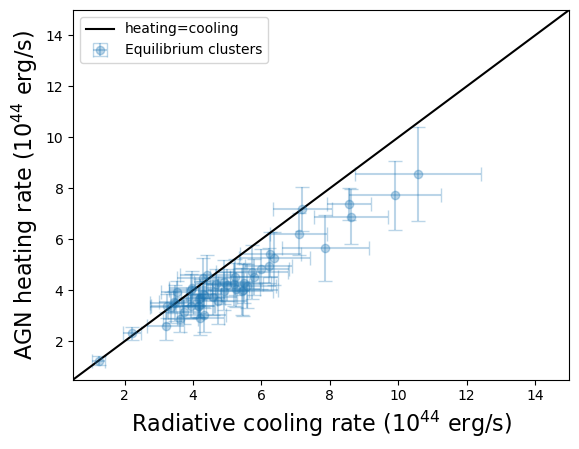

In [226]:
fig = plt.figure()
plt.errorbar(np.divide(eq_cooling_rates,1e44), np.divide(eq_heating_rates,1e44),
             xerr=[[c.minus for c in np.divide(eq_cooling_rates,1e44)],[c.plus for c in np.divide(eq_cooling_rates,1e44)]],
             yerr=[[h.minus for h in np.divide(eq_cooling_rates,1e44)],[h.plus for h in np.divide(eq_cooling_rates,1e44)]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label='Equilibrium clusters')

plt.plot([0, 16], [0, 16], label='heating=cooling', c='k')
plt.ylabel(f'$\mathrm{{AGN~heating~rate~(10^{{44}}~erg/s)}}$', size=16)
plt.xlabel(f'$\mathrm{{Radiative~cooling~rate~(10^{{44}}~erg/s)}}$', size=16)
plt.xlim(0.5, 15)
plt.ylim(0.5, 15)
plt.legend()
plt.show()

In [227]:
len(equilibrium_clusters)

49

In [229]:
with open('data/equilibrium_clusters.pkl', 'rb') as file:
    # Load the data into nfws_subset variable
    nfws_subset = pickle.load(file)
len(nfws_subset)

49

In [231]:
dataset, variances = load_data_and_var()
nfws_werr = generate_nfws_from_combined_dataset_werr(dataset, variances, rmin=0.0001)

In [232]:
len(nfws_werr)

173